### Goal: Audit Camden Council spending
> This dataset contains **408,317 transactions**.
> I used vectorised cleaning operations (Regex/Numpy logic) to ensure performance across a large-scale public sector dataset.
> Please see the end of the project for my conclusions


### Data cleaning progress
- [x] Missing values
- [x] Consolidation of naming
- [x] Investigation of outliers

---

### 1.  Missing values
The raw data contained over 7,000 NaNs in `Irrecoverable VAT Amount GBP`. 
> **Decision:** Since the column otherwise consisted entirely of 0 values, I replaced the NaNs with 0.

There was one other NaN value in `Beneficiary Name`.
> **Decision:** I elected to drop the relevant row as it was statistically insignicant in the context of over 400,000 rows.

### 2. Consolidation of naming
The raw data contained multiple variations for hidden identities, specifically `redacted` and `xxxxredactedxxxx`.
> **Decision:** I used a Regular Expression `.*redacted.*` with the `case=False` flag. This ensures that any string containing "redacted" is captured regardless of padding characters or capitalisation, preventing the 'Volume of Spend' from being split across multiple rows.

### 3. Statutory Levy Outliers
During the `describe()` phase, a maximum value of £31.5m was identified.

> **Observation:** This transaction relates to the Greater London Authority (GLA). While it is a legitimate payment, its scale is three orders of magnitude larger than the mean. I have kept it in the primary DataFrame but will use a filtered subset for a supplier-specific visualisation to maintain a readable scale.


In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [66]:
cc_spending = pd.read_csv('Camden_Council_Spend_Over_500_GBP.csv')

In [5]:
cc_spending.head()

,Organisation Label,Organisation URI,Payment Date,Payment Month,Payment Year,Financial Year,Beneficiary Name,Purpose,Organisational Unit,Amount GBP,Irrecoverable VAT Amount GBP,Latest Financial Year,Latest Year,Latest Month,Unique Identifier
0,London Borough of Camden,http://opendatacommunities.org/id/london-borou...,20/01/2026,January,2026,2025/2026,1 LADY SOMERSET MANAGEMENT LTD,Service Charges,Homes and Communities HRA,1122.39,0.0,Yes,Yes,Yes,jan-26-4450
1,London Borough of Camden,http://opendatacommunities.org/id/london-borou...,15/01/2026,January,2026,2025/2026,2ND TIER AGENCY - PULSE,Professional Services General,"Investment, Place and Opportunity GF",1152.00,0.0,Yes,Yes,Yes,jan-26-1381
2,London Borough of Camden,http://opendatacommunities.org/id/london-borou...,23/01/2026,January,2026,2025/2026,2ND TIER AGENCY - PULSE,Professional Services General,"Investment, Place and Opportunity GF",1152.00,0.0,Yes,Yes,Yes,jan-26-1382
3,London Borough of Camden,http://opendatacommunities.org/id/london-borou...,05/01/2026,January,2026,2025/2026,31TEN CONSULTING,Consultancy Fees,"Investment, Place and Opportunity GF",6000.00,0.0,Yes,Yes,Yes,jan-26-6390
4,London Borough of Camden,http://opendatacommunities.org/id/london-borou...,05/01/2026,January,2026,2025/2026,31TEN CONSULTING,Consultancy Fees,"Investment, Place and Opportunity GF",6000.00,0.0,Yes,Yes,Yes,jan-26-6391


In [6]:
cc_spending.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408317 entries, 0 to 408316
Data columns (total 15 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Organisation Label            408317 non-null  object 
 1   Organisation URI              408317 non-null  object 
 2   Payment Date                  408317 non-null  object 
 3   Payment Month                 408317 non-null  object 
 4   Payment Year                  408317 non-null  int64  
 5   Financial Year                408317 non-null  object 
 6   Beneficiary Name              408316 non-null  object 
 7   Purpose                       408317 non-null  object 
 8   Organisational Unit           408317 non-null  object 
 9   Amount GBP                    408317 non-null  float64
 10  Irrecoverable VAT Amount GBP  401206 non-null  float64
 11  Latest Financial Year         408317 non-null  object 
 12  Latest Year                   408317 non-nul

In [7]:
cc_spending.describe()

,Payment Year,Amount GBP,Irrecoverable VAT Amount GBP
count,408317.000000,4.083170e+05,401206.0
mean,2022.289831,1.362498e+04,0.0
std,2.004117,2.152789e+05,0.0
min,2019.000000,5.000100e+02,0.0
25%,2021.000000,1.000000e+03,0.0
50%,2022.000000,1.820540e+03,0.0
75%,2024.000000,4.603500e+03,0.0
max,2026.000000,3.155457e+07,0.0


In [8]:
cc_spending.nlargest(1, 'Amount GBP')

,Organisation Label,Organisation URI,Payment Date,Payment Month,Payment Year,Financial Year,Beneficiary Name,Purpose,Organisational Unit,Amount GBP,Irrecoverable VAT Amount GBP,Latest Financial Year,Latest Year,Latest Month,Unique Identifier
107839,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,07/09/2020,September,2020,2020/2021,GREATER LONDON AUTHORITY,Levies Paid,Collection Fund B3,31554572.0,0.0,No,No,No,sep-20-3944


In [9]:
unit_summary=cc_spending.groupby('Organisational Unit')['Amount GBP'].agg(['count', 'sum'])
print(unit_summary.sort_values(by='sum', ascending=False).head(10))

                                 count           sum
Organisational Unit                                 
Camden Council                    8084  1.037669e+09
Supporting People GF            141400  6.702899e+08
Supporting Communities GF        57007  6.644173e+08
Collection Fund B3                  69  6.222254e+08
Property Management              10169  4.932876e+08
Supporting Communities HRA       51140  4.790905e+08
Adults and Health                67122  3.973299e+08
Development                       8105  3.735712e+08
Corporate Services GF            17466  2.011595e+08
Environment and Sustainability    7525  1.312094e+08


In [10]:
cc_spending['Organisational Unit'].value_counts()

Organisational Unit
Supporting People GF                                      141400
Adults and Health                                          67122
Supporting Communities GF                                  57007
Supporting Communities HRA                                 51140
Children & Learning                                        23563
Corporate Services GF                                      17466
Property Management                                        10169
Development                                                 8105
Camden Council                                              8084
Environment and Sustainability                              7525
Homes and Communities HRA                                   4084
Investment, Place and Opportunity GF                        2557
Public Health GF                                            2083
Non Departmental GF                                         2081
Recreation                                                  1181
Place

In [11]:
cc_spending['Purpose'].value_counts()

Purpose
Long Term Support Community Homecare           63336
Long Term Support Community Direct Payments    43942
Rents Payable                                  32374
Responsive Repairs Costs                       21281
Long Term Residential Spot Contract            19253
                                               ...  
Recharged Grant Income                             1
Council Tax Income                                 1
Lightning Conductor Maintenance                    1
Other Creditors Central Government Bodies          1
Vehicle Licensing                                  1
Name: count, Length: 262, dtype: int64

In [12]:
cc_spending['Beneficiary Name'].value_counts()

Beneficiary Name
xxxxREDACTEDxxxx                 49257
REDACTED                         16096
HARTWIG CARE LIMITED             10447
MIHOMECARE                        9479
RATHER HOME CARE LTD              7452
                                 ...  
Ise Murphy-Morris                    1
Lime Hut Limited                     1
GRAND UNION HOUSING GROUP LTD        1
SPACEKRAFT                           1
GOODMAN RAY SOLICITORS               1
Name: count, Length: 6188, dtype: int64

In [13]:
cc_spending['Beneficiary Name'] = cc_spending['Beneficiary Name'].str.replace('.*redacted.*', 'redacted', case=False, regex=True)

In [14]:
cc_spending['Payment Date'] = pd.to_datetime(cc_spending['Payment Date'], dayfirst=True)

In [15]:
print(cc_spending['Payment Date'].dtype)

datetime64[ns]


In [16]:
cc_spending.set_index('Payment Date', inplace=True)

In [17]:
cc_spending.index

DatetimeIndex(['2026-01-20', '2026-01-15', '2026-01-23', '2026-01-05',
               '2026-01-05', '2026-01-05', '2026-01-05', '2026-01-05',
               '2026-01-05', '2026-01-05',
               ...
               '2025-08-29', '2025-08-29', '2025-08-29', '2025-08-29',
               '2025-08-29', '2025-08-29', '2025-08-29', '2025-08-29',
               '2025-08-29', '2025-08-29'],
              dtype='datetime64[ns]', name='Payment Date', length=408317, freq=None)

In [18]:
cc_spending.sort_index(inplace=True)

In [19]:
cc_spending.head()

,Organisation Label,Organisation URI,Payment Month,Payment Year,Financial Year,Beneficiary Name,Purpose,Organisational Unit,Amount GBP,Irrecoverable VAT Amount GBP,Latest Financial Year,Latest Year,Latest Month,Unique Identifier
Payment Date,,,,,,,,,,,,,,
2019-02-06,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,February,2019,2018/2019,VOLKERHIGHWAYS LIMITED,Capital Main Works,Place Management,8017.78,NaN,No,No,No,pre_april_2019-365795
2019-02-06,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,February,2019,2018/2019,MINDS LTD T/A IGAR HOTEL,Rents Payable,Supporting People GF,744.00,NaN,No,No,No,pre_april_2019-365744
2019-02-06,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,February,2019,2018/2019,MINDS LTD T/A IGAR HOTEL,Rents Payable,Supporting People GF,720.00,NaN,No,No,No,pre_april_2019-365743
2019-02-06,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,February,2019,2018/2019,MINDS LTD T/A IGAR HOTEL,Rents Payable,Supporting People GF,1170.00,NaN,No,No,No,pre_april_2019-365740
2019-02-06,London Borough of Camden,https://opendatacommunities.org/doc/london-bor...,February,2019,2018/2019,MINDS LTD T/A IGAR HOTEL,Rents Payable,Supporting People GF,744.00,NaN,No,No,No,pre_april_2019-365742


In [20]:
missing_vat = cc_spending['Irrecoverable VAT Amount GBP'].isna().sum()
print(f'There are {missing_vat} rows with missing VAT values.')

There are 7111 rows with missing VAT values.


In [21]:
cc_spending['Irrecoverable VAT Amount GBP'] = cc_spending['Irrecoverable VAT Amount GBP'].fillna(0)

In [22]:
missing_vat = cc_spending['Irrecoverable VAT Amount GBP'].isna().sum()
print(f'There are {missing_vat} rows with missing VAT values.')


There are 0 rows with missing VAT values.


In [23]:
negative_spend = cc_spending[cc_spending['Amount GBP'] < 0]
print(f'There are {len(negative_spend)} negative transactions')

There are 0 negative transactions


In [24]:
cc_spending['Beneficiary Name'] = cc_spending['Beneficiary Name'].str.strip().str.lower()

In [26]:
cc_spending.isna().sum()

Organisation Label              0
Organisation URI                0
Payment Month                   0
Payment Year                    0
Financial Year                  0
Beneficiary Name                1
Purpose                         0
Organisational Unit             0
Amount GBP                      0
Irrecoverable VAT Amount GBP    0
Latest Financial Year           0
Latest Year                     0
Latest Month                    0
Unique Identifier               0
dtype: int64

In [27]:
cc_spending.dropna(inplace=True)

In [28]:
cc_spending.isna().sum()

Organisation Label              0
Organisation URI                0
Payment Month                   0
Payment Year                    0
Financial Year                  0
Beneficiary Name                0
Purpose                         0
Organisational Unit             0
Amount GBP                      0
Irrecoverable VAT Amount GBP    0
Latest Financial Year           0
Latest Year                     0
Latest Month                    0
Unique Identifier               0
dtype: int64

In [29]:
cc_spending['Beneficiary Name'] = cc_spending['Beneficiary Name'].str.title()

top_10_beneficiaries= (cc_spending.groupby('Beneficiary Name')['Amount GBP']
    .sum()
    .sort_values(ascending=False)
    .head(10))      

print(top_10_beneficiaries)

Beneficiary Name
Greater London Authority                     6.742714e+08
Hmrc Central Payroll                         5.469392e+08
Redacted                                     3.161033e+08
Matrix Scm Limited                           1.878175e+08
Veolia Environmental Services (Uk) Plc       1.693647e+08
Mclaren Construction (Major Projects) Ltd    8.645094e+07
Hill Partnership Ltd                         7.509520e+07
Total Gas And Power Ltd                      7.421138e+07
Wates Construction Ltd                       7.080667e+07
Lendlease Consulting (Europe) Ltd            6.855078e+07
Name: Amount GBP, dtype: float64


In [30]:
pd.options.display.float_format = '{:,.2f}'.format
print(top_10_beneficiaries)


Beneficiary Name
Greater London Authority                    674,271,378.72
Hmrc Central Payroll                        546,939,214.72
Redacted                                    316,103,337.61
Matrix Scm Limited                          187,817,541.25
Veolia Environmental Services (Uk) Plc      169,364,722.23
Mclaren Construction (Major Projects) Ltd    86,450,944.16
Hill Partnership Ltd                         75,095,197.89
Total Gas And Power Ltd                      74,211,383.14
Wates Construction Ltd                       70,806,674.11
Lendlease Consulting (Europe) Ltd            68,550,780.77
Name: Amount GBP, dtype: float64


In [33]:
print(cc_spending[cc_spending['Beneficiary Name'].str.contains('redacted', case=False)]['Amount GBP'].sum())

316103337.61


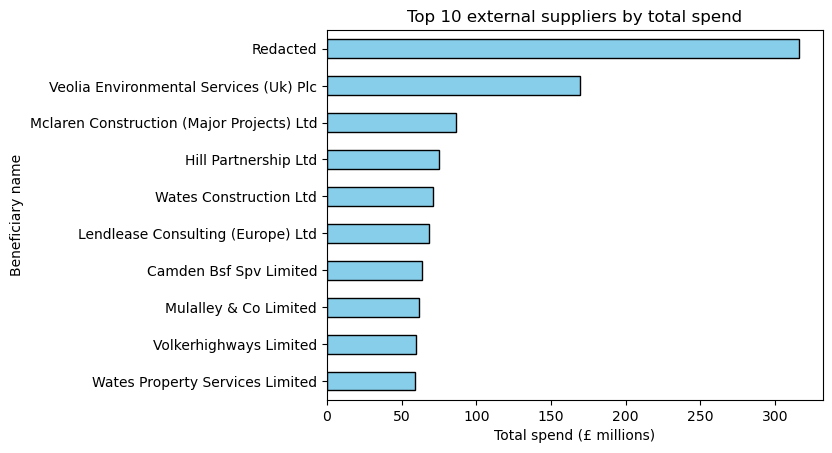

In [40]:
clean_top_10 = cc_spending[(cc_spending['Beneficiary Name'] == 'Redacted') | (cc_spending['Beneficiary Name'] != 'Greater London Authority') & (cc_spending['Organisational Unit'] != 'Camden Council')]
top_suppliers = clean_top_10.groupby('Beneficiary Name')['Amount GBP'].sum().sort_values(ascending=False).head(10)
(top_suppliers/1_000_000).plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Top 10 external suppliers by total spend')
plt.xlabel('Total spend (£ millions)', fontsize=10)
plt.ylabel('Beneficiary name', fontsize=10)
plt.gca().invert_yaxis()
plt.show()



### Key Finding: The single largest category of expenditure (excluding statutory levies and payroll) is 'Redacted' at £316 million. This indicates a significant volume of spending where the beneficiary identity is protected, likely due to sensitive social care payments or data protection requirements.

In [58]:
redacted_only = cc_spending[cc_spending['Beneficiary Name'] == 'Redacted']
top_5_redacted_by_unit = redacted_only.groupby('Organisational Unit')['Amount GBP'].sum().sort_values(ascending=False).head(5)
print(top_5_redacted_by_unit)

Organisational Unit
Camden Council                   137,063,158.31
Supporting People GF              76,841,850.38
Adults and Health                 40,355,166.51
Environment and Sustainability    14,640,238.52
Children & Learning               14,325,667.78
Name: Amount GBP, dtype: float64


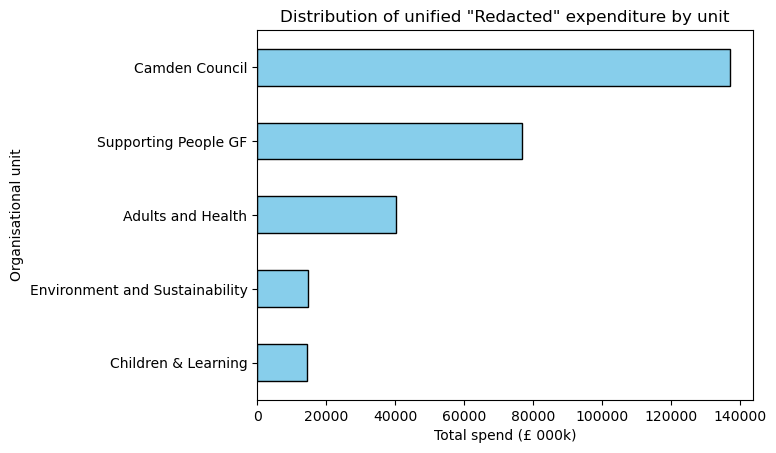

In [63]:
(top_5_redacted_by_unit/1_000).plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Distribution of unified "Redacted" expenditure by unit')
plt.xlabel('Total spend (£ 000k)')
plt.ylabel('Organisational unit')
plt.gca().invert_yaxis()

### Final Project Conclusions

By systematically cleaning the Camden Council expenditure data, analysis uncovered several critical insights that were hidden in the raw dataset:

1. **The Transparency Gap:** Once unified, 'Redacted' beneficiaries represent the largest single area of spend (£316m). 
2. **Internal vs. External:** The majority of redacted spend (£137m) occurs within the 'Camden Council' organisational unit, suggesting these are internal transfers or sensitive payroll data rather than commercial procurement.
3. **Statutory Scale:** The £31.5m payment to the GLA was identified as a non-commercial outlier, representing a statutory levy rather than a supplier relationship.

> **Analyst's Verdict:** This project demonstrates that without rigorous data cleaning — specifically handling casing, regex unification, and outlier investigation — the "top-line" figures of government spending would be significantly misleading.